## Features Inspected

FHR = fetal heart rate; UC = uterine contraction.

| Feature | Meaning |
|---|---|
| F_EC_STTF | FHR S-transform energy complexity |
| F_EF_STTF | FHR S-transform energy fraction |
| U_LPF_ST01 | Low-pass UC S-transform component |
| U_TR_RD | Contraction rise-to-decay duration ratio |
| U_TN | Transitional contraction count |
| F_VD_N | Likely variable-deceleration count* |
| F_K | Likely FHR kurtosis (tail weight)* |

Definitions follow the supplied guide; * marks unconfirmed meanings.
Unusual values are not automatically errors.

In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(
    r"C:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features"
)

# Load training data for outlier inspection.
train_df = pd.read_csv(ROOT / "data/processed/train.csv")

feature_cols = [
    col for col in train_df.columns
    if col.startswith(("F_", "U_", "FU_"))
]

X_train = train_df[feature_cols]

print("Training data loaded:", X_train.shape)

Training data loaded: (14540, 103)


In [5]:
# Choose one feature to inspect.
feature = "F_EC_STTF"
values = X_train[feature]

q1 = values.quantile(0.25)
q3 = values.quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

flagged = (values < lower) | (values > upper)

print("Feature:", feature)
print("Lower boundary:", lower)
print("Upper boundary:", upper)
print("Flagged values:", flagged.sum())
print(f"Flagged percentage: {flagged.mean():.2%}")

# Show some recordings containing flagged values.
display(train_df.loc[
    flagged, ["record_id", feature, "figo_label"]
].head(10))


Feature: F_EC_STTF
Lower boundary: 245500000000000.0
Upper boundary: 449500000000000.0
Flagged values: 1920
Flagged percentage: 13.20%


,record_id,F_EC_STTF,figo_label
18,10035_1_210208000001,2.230000e+14,1
146,10322_1_210208000001,2.000000e+14,1
194,10416_1_210208000001,2.090000e+14,1
305,10657_1_210208000001,2.270000e+14,1
348,10750_1_210208000001,1.450000e+14,1
468,11026_1_210208000001,2.110000e+14,1
488,11067_1_210208000001,5.990000e+14,1
501,110_1_210208000001,4.500000e+14,0
657,113_1_210208000001,4.530000e+14,0
675,11446_1_210208000001,6.060000e+13,1


C:\Users\Rathishan\AppData\Local\Temp\ipykernel_25928\2744761588.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(values, vert=True)


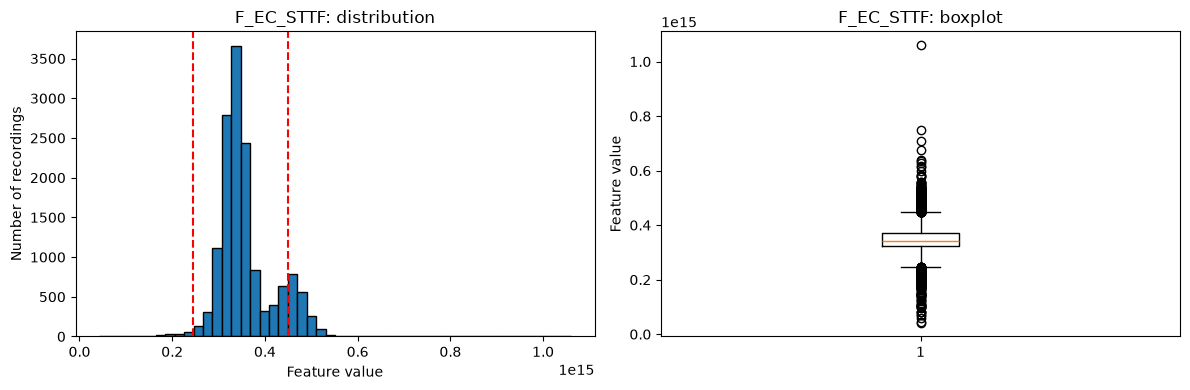

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(values, bins=50, edgecolor="black")
axes[0].axvline(lower, color="red", linestyle="--")
axes[0].axvline(upper, color="red", linestyle="--")
axes[0].set_title(f"{feature}: distribution")
axes[0].set_xlabel("Feature value")
axes[0].set_ylabel("Number of recordings")

axes[1].boxplot(values, vert=True)
axes[1].set_title(f"{feature}: boxplot")
axes[1].set_ylabel("Feature value")

plt.tight_layout()
plt.show()

### Observation: F_EC_STTF

Normal and abnormal recordings have overlapping central values.
Abnormal recordings show a wider overall range, including more
visually apparent extreme values.

These values are not confirmed errors. Keep the original data
unchanged and evaluate any capping through a separate experiment.

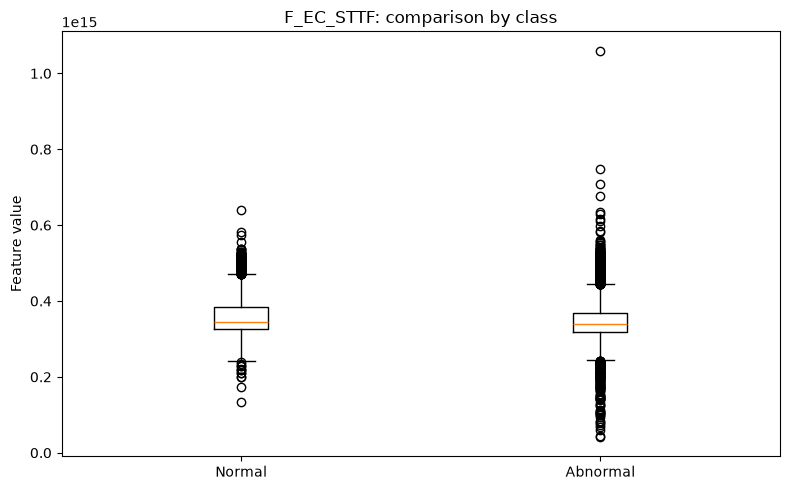

In [7]:
normal = train_df.loc[train_df["figo_label"] == 0, feature]
abnormal = train_df.loc[train_df["figo_label"] == 1, feature]

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [normal, abnormal],
    tick_labels=["Normal", "Abnormal"]
)

ax.set_title(f"{feature}: comparison by class")
ax.set_ylabel("Feature value")

plt.tight_layout()
plt.show()

In [8]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

val_df = pd.read_csv(ROOT / "data/processed/val.csv")

X_val = val_df[feature_cols]
y_train = train_df["figo_label"]
y_val = val_df["figo_label"]

# Copies: the original data stays unchanged.
X_train_capped = X_train.copy()
X_val_capped = X_val.copy()

In [9]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

val_df = pd.read_csv(ROOT / "data/processed/val.csv")

X_val = val_df[feature_cols]
y_train = train_df["figo_label"]
y_val = val_df["figo_label"]

# Copies: the original data stays unchanged.
X_train_capped = X_train.copy()
X_val_capped = X_val.copy()

In [10]:
feature = "F_EC_STTF"

# Learn boundaries from training data only.
q1 = X_train[feature].quantile(0.25)
q3 = X_train[feature].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

assert iqr > 0, "Zero IQR: inspect this feature before capping."

# Apply the SAME boundaries to both datasets.
X_train_capped[feature] = X_train[feature].clip(lower, upper)
X_val_capped[feature] = X_val[feature].clip(lower, upper)

print("Training values changed:",
      X_train[feature].ne(X_train_capped[feature]).sum())
print("Validation values changed:",
      X_val[feature].ne(X_val_capped[feature]).sum())

Training values changed: 1920
Validation values changed: 411


In [11]:
capped_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2,
)

capped_model.fit(X_train_capped, y_train)

print("Training complete.")

Training complete.


In [12]:
capped_pred = capped_model.predict(X_val_capped)

print("After capping F_EC_STTF — validation results\n")
print(f"Accuracy:  {accuracy_score(y_val, capped_pred):.2%}")
print(f"Precision: {precision_score(y_val, capped_pred, zero_division=0):.2%}")
print(f"Recall:    {recall_score(y_val, capped_pred, zero_division=0):.2%}")
print(f"F1 score:  {f1_score(y_val, capped_pred, zero_division=0):.2%}")

print("\nOriginal baseline:")
print("Accuracy: 93.10%")
print("Precision: 93.25%")
print("Recall: 93.97%")
print("F1 score: 93.61%")

After capping F_EC_STTF — validation results

Accuracy:  93.16%
Precision: 93.57%
Recall:    93.74%
F1 score:  93.65%

Original baseline:
Accuracy: 93.10%
Precision: 93.25%
Recall: 93.97%
F1 score: 93.61%


Capping F_EC_STTF using training-derived IQR boundaries slightly increased validation accuracy, precision, and abnormal-class F1, but reduced recall. The F1 improvement was marginal, so the benefit remains uncertain.

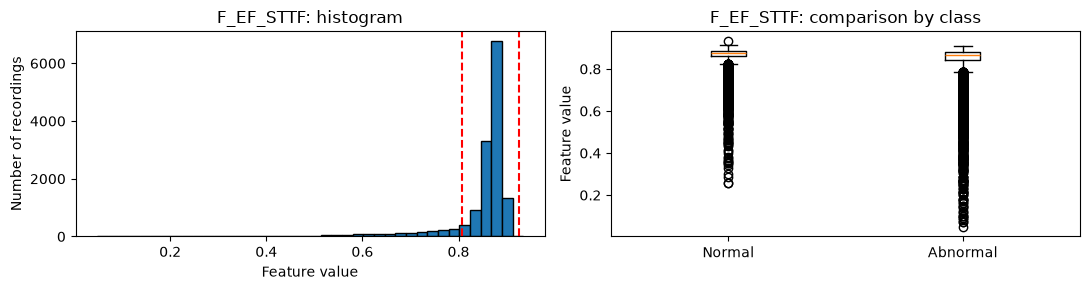

F_EF_STTF: 1860 flagged (12.79%); zero IQR: False


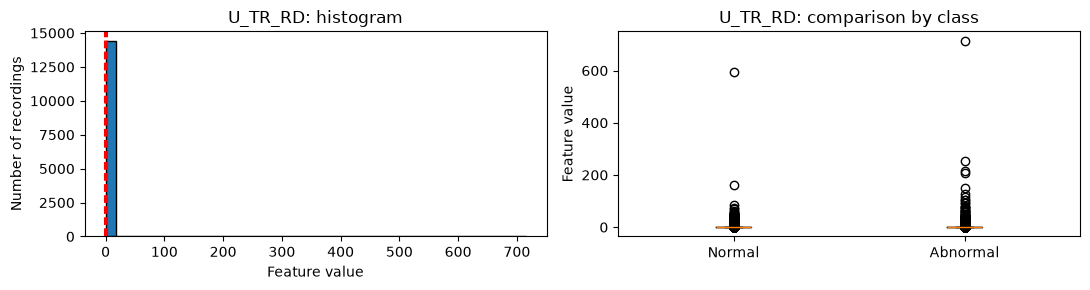

U_TR_RD: 1618 flagged (11.13%); zero IQR: False


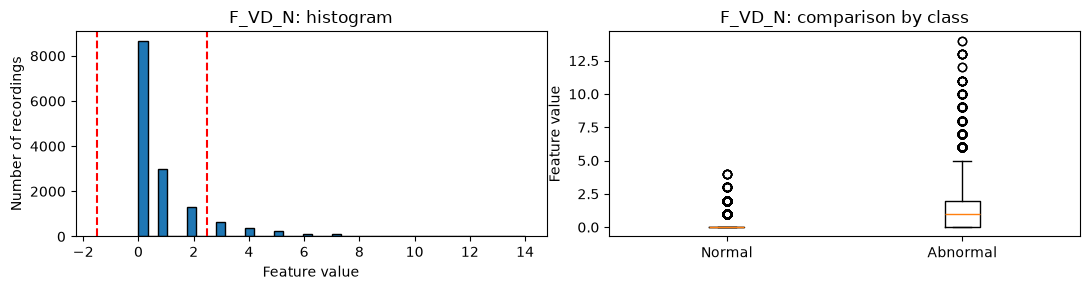

F_VD_N: 1560 flagged (10.73%); zero IQR: False


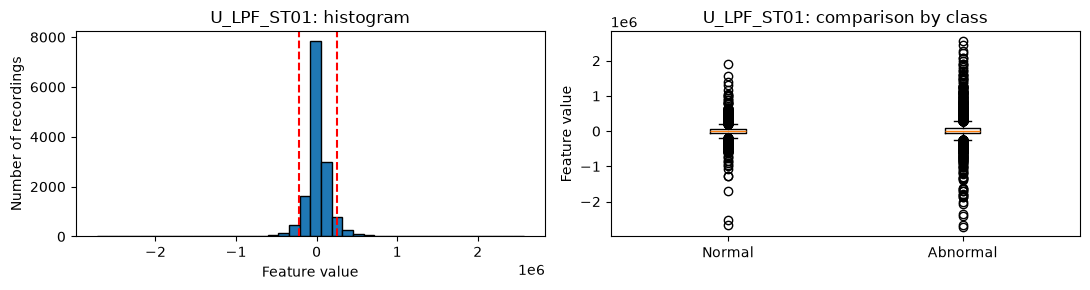

U_LPF_ST01: 1555 flagged (10.69%); zero IQR: False


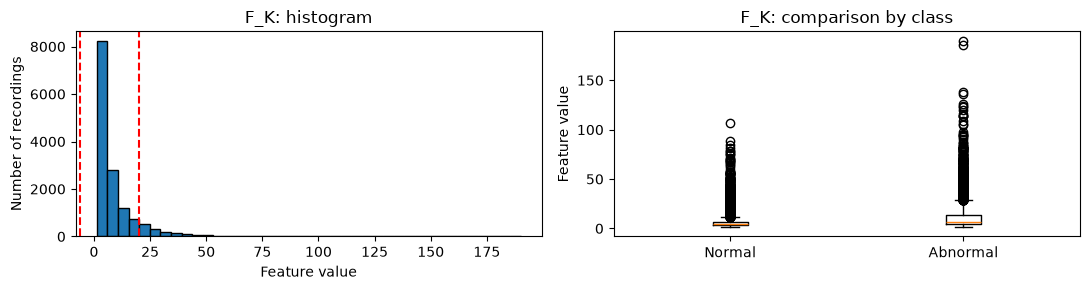

F_K: 1551 flagged (10.67%); zero IQR: False


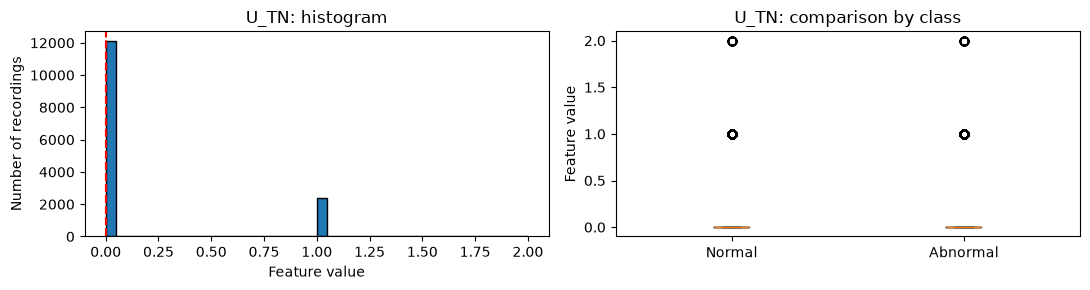

U_TN: 2434 flagged (16.74%); zero IQR: True


In [ ]:
features_to_check = [
    "F_EF_STTF",
    "U_TR_RD",
    "F_VD_N",
    "U_LPF_ST01",
    "F_K",
    "U_TN",
]

for feature_name in features_to_check:
    values = X_train[feature_name]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    normal = values[y_train == 0]
    abnormal = values[y_train == 1]

    fig, axes = plt.subplots(1, 2, figsize=(11, 3))

    axes[0].hist(values, bins=40, edgecolor="black")
    axes[0].axvline(lower, color="red", linestyle="--")
    axes[0].axvline(upper, color="red", linestyle="--")
    axes[0].set_title(f"{feature_name}: histogram")
    axes[0].set_xlabel("Feature value")
    axes[0].set_ylabel("Number of recordings")

    axes[1].boxplot(
        [normal, abnormal],
        tick_labels=["Normal", "Abnormal"],
    )
    axes[1].set_title(f"{feature_name}: comparison by class")
    axes[1].set_ylabel("Feature value")

    plt.tight_layout()
    plt.show()

    flagged = (values < lower) | (values > upper)
    print(
        f"{feature_name}: {flagged.sum()} flagged "
        f"({flagged.mean():.2%}); zero IQR: {iqr == 0}"
    )

## Proposal: Group features by distribution pattern

### Purpose

Instead of inspecting 103 features individually at the beginning, group features with broadly similar distribution patterns and inspect representative examples first.

This reduces repetitive plotting while covering different patterns. Every feature will still receive an individual statistical check before any treatment.

### Initial analysis

The grouping uses the original training data only. It considers:

- **Skewness:** whether the distribution extends farther toward high or low values.
- **Tail weight:** how strongly extreme values influence the distribution.
- **Zero percentage:** whether many observations are zero.
- **Distinct values:** whether a feature contains only a few integer values.
- **IQR:** whether the middle 50% has any spread.

These are provisional statistical groups, not proof that their features have identical distributions or meanings.

### Groups and selected features

| Distribution group | Number of features | Features selected for visual inspection | Reason |
|---|---:|---|---|
| Zero IQR | 4 | `U_TN` | Demonstrates why automatic IQR capping can erase nonzero values |
| Small discrete integer values | 3 | `F_VD_N` | Shows a count-like distribution with different patterns by class |
| Zero-heavy, nonzero IQR | 1 | `U_TR_RD` | Many zeros with a long upper tail |
| Right-skewed | 49 | `F_K` | Represents a distribution extending toward high values |
| Left-skewed | 12 | `F_EF_STTF` | Represents a distribution extending toward low values |
| Limited skewness, heavy tails | 4 | `U_LPF_ST01` | Represents a central concentration with extremes on both sides |
| Other features with limited skewness | 30 | `F_BL` and `F_EC_STTF` | Compare another distribution with the feature already investigated |
| **Total** | **103** | **8 representative features** | |

The four zero-IQR features are `U_TN`, `F_ED_N`, `F_LD_N`, and `F_PD_N`. They require separate care.

### Grouping rules

Apply the following rules in order:

1. Zero IQR → zero-IQR group.
2. Integer-valued with no more than 20 distinct values → small-discrete group.
3. At least 50% zeros → zero-heavy group.
4. Skewness above 1 → right-skewed group.
5. Skewness below −1 → left-skewed group.
6. Remaining features with excess kurtosis above 3 → limited skewness with heavy tails.
7. Remaining features → other features with limited skewness.

These thresholds organise inspection; they do not establish normality or identify confirmed errors.

### Inspection procedure

1. Inspect histograms and normal/abnormal boxplots for the selected features.
2. Use zoomed or alternative-scale plots where extreme values hide the main distribution.
3. Check additional members when a group contains different-looking patterns.
4. Consult feature definitions before deciding whether values are implausible.
5. Document which features are preserved or included in a treatment experiment.

### Treatment and evaluation

Representative selection is for visual inspection only. Each treated feature must have its own training-derived boundaries.

Preserve the original data and avoid automatically applying one treatment to an entire group. Compare justified treatments using the same XGBoost settings and validation data. Keep the test set untouched.

In [ ]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Load validation data; use original training features.
val_df = pd.read_csv(ROOT / "data/processed/val.csv")

X_train = train_df[feature_cols].copy()
y_train = train_df["figo_label"]

X_val = val_df[feature_cols].copy()
y_val = val_df["figo_label"]

# Check that patients do not overlap between the two sets.
assert set(train_df["patient_id"]).isdisjoint(
    set(val_df["patient_id"])
)

selected_features = [
    "F_EC_STTF",
    "F_EF_STTF",
    "U_LPF_ST01",
    "F_K",
]

# Calculate separate boundaries for each selected feature.
# Only TRAINING data is used to learn these boundaries.
q1 = X_train[selected_features].quantile(0.25)
q3 = X_train[selected_features].quantile(0.75)
iqr = q3 - q1

assert (iqr > 0).all(), "Inspect zero-IQR features separately."

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# Create treated copies, starting from the original data.
X_train_capped = X_train.copy()
X_val_capped = X_val.copy()

for column in selected_features:
    X_train_capped[column] = X_train[column].clip(
        lower[column], upper[column]
    )
    X_val_capped[column] = X_val[column].clip(
        lower[column], upper[column]
    )

# Show how many values changed in each selected column.
changes = pd.DataFrame({
    "Training values changed": (
        X_train[selected_features]
        .ne(X_train_capped[selected_features])
        .sum()
    ),
    "Validation values changed": (
        X_val[selected_features]
        .ne(X_val_capped[selected_features])
        .sum()
    ),
})

display(changes)

# Identical settings for both models.
settings = dict(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2,
)

experiments = {
    "Original baseline": (X_train, X_val),
    "Four-feature IQR capping": (
        X_train_capped, X_val_capped
    ),
}

results = {}
predictions = {}

for name, (training_inputs, validation_inputs) in experiments.items():
    experiment_model = XGBClassifier(**settings)
    experiment_model.fit(training_inputs, y_train)

    predicted = experiment_model.predict(validation_inputs)
    predictions[name] = predicted

    results[name] = {
        "Accuracy": accuracy_score(y_val, predicted),
        "Abnormal precision": precision_score(
            y_val, predicted, zero_division=0
        ),
        "Abnormal recall": recall_score(
            y_val, predicted, zero_division=0
        ),
        "Abnormal F1": f1_score(
            y_val, predicted, zero_division=0
        ),
    }

comparison = pd.DataFrame.from_dict(results, orient="index")

print("Validation performance:")
display(comparison.style.format("{:.2%}"))

print("Change after capping — percentage points:")
difference = (
    comparison.loc["Four-feature IQR capping"]
    - comparison.loc["Original baseline"]
) * 100

display(difference.round(3).to_frame("Change"))

for name, predicted in predictions.items():
    print(f"\n{name}:")
    display(pd.DataFrame(
        confusion_matrix(y_val, predicted, labels=[0, 1]),
        index=["Actual normal", "Actual abnormal"],
        columns=["Predicted normal", "Predicted abnormal"],
    ))

,Training values changed,Validation values changed
F_EC_STTF,1920,411
F_EF_STTF,1860,392
U_LPF_ST01,1555,297
F_K,1551,343


Validation performance:


,Accuracy,Abnormal precision,Abnormal recall,Abnormal F1
Original baseline,93.10%,93.25%,93.97%,93.61%
Four-feature IQR capping,92.42%,92.50%,93.50%,93.00%


Change after capping — percentage points:


,Change
Accuracy,-0.674
Abnormal precision,-0.747
Abnormal recall,-0.477
Abnormal F1,-0.614



Original baseline:


,Predicted normal,Predicted abnormal
Actual normal,1325,114
Actual abnormal,101,1575



Four-feature IQR capping:


,Predicted normal,Predicted abnormal
Actual normal,1312,127
Actual abnormal,109,1567


### Experiment 2: IQR capping of four features

Applied training-derived IQR boundaries to F_EC_STTF,
F_EF_STTF, U_LPF_ST01, and F_K. All recordings were retained,
and XGBoost settings were unchanged.

Validation accuracy decreased from 93.10% to 92.42%.
Abnormal-class F1 decreased from 93.61% to 93.00%.
The model made 21 additional incorrect predictions.

This combined treatment did not improve validation performance.
Retain the original baseline as the preferred approach for now.
The experiment does not identify which individual feature
contributed to the decrease.

### Experiment 3: Individual Feature Capping

We will test IQR capping separately on `F_EF_STTF`, `U_LPF_ST01`, and `F_K`, starting from the original data each time and applying training-derived boundaries to training and validation copies.
Each experiment will use identical XGBoost settings and compare validation accuracy, precision, recall, and F1 against the baseline, while leaving the test set untouched.

In [ ]:
# Reload original data so earlier capping cannot carry over.
train_original = pd.read_csv(ROOT / "data/processed/train.csv")
val_original = pd.read_csv(ROOT / "data/processed/val.csv")

features = [
    c for c in train_original.columns
    if c.startswith(("F_", "U_", "FU_"))
]

X_train_original = train_original[features]
X_val_original = val_original[features]
y_train_original = train_original["figo_label"]
y_val_original = val_original["figo_label"]

settings = dict(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2,
)

# None means no capping: recalculate the baseline for comparison.
experiments = [
    None,
    "F_EF_STTF",
    "U_LPF_ST01",
    "F_K",
]

rows = []

for column in experiments:
    # Start from the ORIGINAL data every time.
    Xtr = X_train_original.copy()
    Xva = X_val_original.copy()

    training_changed = 0
    validation_changed = 0

    if column is not None:
        q1 = Xtr[column].quantile(0.25)
        q3 = Xtr[column].quantile(0.75)
        iqr = q3 - q1

        assert iqr > 0, f"{column} has zero IQR."

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        Xtr[column] = Xtr[column].clip(lower, upper)
        Xva[column] = Xva[column].clip(lower, upper)

        training_changed = (
            Xtr[column] != X_train_original[column]
        ).sum()
        validation_changed = (
            Xva[column] != X_val_original[column]
        ).sum()

    experiment_model = XGBClassifier(**settings)
    experiment_model.fit(Xtr, y_train_original)
    predicted = experiment_model.predict(Xva)

    rows.append({
        "Experiment": (
            "Original baseline"
            if column is None
            else f"Cap {column} only"
        ),
        "Accuracy": accuracy_score(y_val_original, predicted),
        "Precision": precision_score(
            y_val_original, predicted, zero_division=0
        ),
        "Recall": recall_score(
            y_val_original, predicted, zero_division=0
        ),
        "F1": f1_score(
            y_val_original, predicted, zero_division=0
        ),
        "Training values changed": training_changed,
        "Validation values changed": validation_changed,
    })

individual_results = pd.DataFrame(rows).set_index("Experiment")

# Calculate changes using unrounded scores.
baseline_f1 = individual_results.loc["Original baseline", "F1"]
individual_results["F1 change (percentage points)"] = (
    individual_results["F1"] - baseline_f1
) * 100

display(individual_results.style.format({
    "Accuracy": "{:.2%}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1": "{:.2%}",
    "Training values changed": "{:.0f}",
    "Validation values changed": "{:.0f}",
    "F1 change (percentage points)": "{:+.3f}",
}))

,Accuracy,Precision,Recall,F1,Training values changed,Validation values changed,F1 change (percentage points)
Experiment,,,,,,,
Original baseline,93.10%,93.25%,93.97%,93.61%,0,0,+0.000
Cap F_EF_STTF only,92.78%,92.90%,93.74%,93.32%,1860,392,-0.293
Cap U_LPF_ST01 only,92.91%,92.87%,94.03%,93.45%,1555,297,-0.163
Cap F_K only,93.00%,93.34%,93.68%,93.51%,1551,343,-0.103


### Experiment 3: Findings

Individual IQR capping of F_EF_STTF, U_LPF_ST01, and F_K reduced validation abnormal-class F1 compared with the original baseline.
Therefore, retain the original feature values for these columns under the current XGBoost settings.

### Experiment 4: Median Replacement

Replace IQR-flagged values in F_EC_STTF with the original training median, using training-derived boundaries for both training and validation copies.
Compare XGBoost validation performance with the original baseline while preserving the original files and leaving the test set untouched.

In [ ]:
# Start from original data.
train_original = pd.read_csv(ROOT / "data/processed/train.csv")
val_original = pd.read_csv(ROOT / "data/processed/val.csv")

features = [
    c for c in train_original.columns
    if c.startswith(("F_", "U_", "FU_"))
]

Xtr_original = train_original[features]
Xva_original = val_original[features]
ytr = train_original["figo_label"]
yva = val_original["figo_label"]

feature = "F_EC_STTF"

# Learn everything from the ORIGINAL training column.
training_values = Xtr_original[feature]

q1 = training_values.quantile(0.25)
q3 = training_values.quantile(0.75)
iqr = q3 - q1

assert iqr > 0, "Zero IQR: inspect before treating."

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
training_median = training_values.median()

# Create fresh copies.
Xtr_median = Xtr_original.copy()
Xva_median = Xva_original.copy()

train_flags = (
    (Xtr_original[feature] < lower)
    | (Xtr_original[feature] > upper)
)
val_flags = (
    (Xva_original[feature] < lower)
    | (Xva_original[feature] > upper)
)

# Replace flagged values using the SAME training median.
Xtr_median.loc[train_flags, feature] = training_median
Xva_median.loc[val_flags, feature] = training_median

print("Training median:", training_median)
print("Training values replaced:", train_flags.sum())
print("Validation values replaced:", val_flags.sum())

settings = dict(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2,
)

experiments = {
    "Original baseline": (Xtr_original, Xva_original),
    "Median replacement": (Xtr_median, Xva_median),
}

results = {}

for name, (training_inputs, validation_inputs) in experiments.items():
    fitted_model = XGBClassifier(**settings)
    fitted_model.fit(training_inputs, ytr)
    predicted = fitted_model.predict(validation_inputs)

    results[name] = {
        "Accuracy": accuracy_score(yva, predicted),
        "Precision": precision_score(
            yva, predicted, zero_division=0
        ),
        "Recall": recall_score(
            yva, predicted, zero_division=0
        ),
        "F1": f1_score(
            yva, predicted, zero_division=0
        ),
    }

median_results = pd.DataFrame.from_dict(results, orient="index")

display(median_results.style.format("{:.2%}"))

difference = (
    median_results.loc["Median replacement"]
    - median_results.loc["Original baseline"]
) * 100

print("Change from baseline — percentage points:")
display(difference.round(3).to_frame("Change"))

Training median: 342000000000000.0
Training values replaced: 1920
Validation values replaced: 411


,Accuracy,Precision,Recall,F1
Original baseline,93.10%,93.25%,93.97%,93.61%
Median replacement,92.65%,93.19%,93.14%,93.17%


Change from baseline — percentage points:


,Change
Accuracy,-0.449
Precision,-0.056
Recall,-0.835
F1,-0.444


### Experiment 4: Findings

F_EC_STTF is described in the supplied guide as FHR S-transform
energy complexity. Replacing its IQR-flagged values with the
training median reduced validation F1 from 93.61% to 93.17%
and recall from 93.97% to 93.14%.

Median replacement did not improve performance under the current
XGBoost settings; retain the original values for this approach.

### Experiment 5: Patient-Grouped Cross-Validation

F_EC_STTF is described in the supplied guide as FHR S-transform
energy complexity.

We selected its IQR-capping treatment for further checking because
it slightly increased validation F1 from 93.61% to 93.65%, while
the other treatments tested reduced F1. However, recall decreased,
so this small improvement is not enough to establish a benefit.

Five-fold patient-grouped cross-validation will check whether
the difference repeats across training subsets. Capping preserves
all recordings, and its boundaries will be learned separately
within each fold using only that fold's fitting data.

This is a stability check, not proof that the flagged values are
errors. The shared validation and test files will not be used.

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, recall_score, f1_score
from xgboost import XGBClassifier

# Use only the shared TRAINING file.
cv_data = pd.read_csv(ROOT / "data/processed/train.csv")

features = [
    c for c in cv_data.columns
    if c.startswith(("F_", "U_", "FU_"))
]

X = cv_data[features]
y = cv_data["figo_label"]
groups = cv_data["patient_id"]

feature = "F_EC_STTF"

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

settings = dict(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2,
)

rows = []

for fold, (train_idx, holdout_idx) in enumerate(
    cv.split(X, y, groups), start=1
):
    X_fit = X.iloc[train_idx].copy()
    X_holdout = X.iloc[holdout_idx].copy()
    y_fit = y.iloc[train_idx]
    y_holdout = y.iloc[holdout_idx]

    assert set(groups.iloc[train_idx]).isdisjoint(
        set(groups.iloc[holdout_idx])
    )

    # Learn boundaries from this fold's fitting portion only.
    q1 = X_fit[feature].quantile(0.25)
    q3 = X_fit[feature].quantile(0.75)
    iqr = q3 - q1
    assert iqr > 0

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    for treatment in ["Original", "Capped"]:
        X_fit_used = X_fit.copy()
        X_holdout_used = X_holdout.copy()

        if treatment == "Capped":
            X_fit_used[feature] = X_fit_used[feature].clip(
                lower, upper
            )
            X_holdout_used[feature] = X_holdout_used[feature].clip(
                lower, upper
            )

        fitted = XGBClassifier(**settings)
        fitted.fit(X_fit_used, y_fit)
        predicted = fitted.predict(X_holdout_used)

        rows.append({
            "Fold": fold,
            "Treatment": treatment,
            "Accuracy": accuracy_score(y_holdout, predicted),
            "Recall": recall_score(
                y_holdout, predicted, zero_division=0
            ),
            "F1": f1_score(
                y_holdout, predicted, zero_division=0
            ),
        })

    print(f"Fold {fold}/5 complete")

cv_results = pd.DataFrame(rows)

print("\nScores for each fold:")
display(cv_results.style.format({
    "Accuracy": "{:.2%}",
    "Recall": "{:.2%}",
    "F1": "{:.2%}",
}))

print("\nAverage scores and standard deviations:")
summary = cv_results.groupby("Treatment")[
    ["Accuracy", "Recall", "F1"]
].agg(["mean", "std"])

display(summary.style.format("{:.2%}"))

# Compare both approaches on exactly the same folds.
paired_f1 = cv_results.pivot(
    index="Fold", columns="Treatment", values="F1"
)

paired_f1["F1 change (percentage points)"] = (
    paired_f1["Capped"] - paired_f1["Original"]
) * 100

print("\nPaired F1 comparison:")
display(paired_f1.style.format({
    "Original": "{:.2%}",
    "Capped": "{:.2%}",
    "F1 change (percentage points)": "{:+.3f}",
}))

Fold 1/5 complete
Fold 2/5 complete
Fold 3/5 complete
Fold 4/5 complete
Fold 5/5 complete

Scores for each fold:


,Fold,Treatment,Accuracy,Recall,F1
0,1,Original,92.37%,93.23%,92.93%
1,1,Capped,91.96%,92.72%,92.54%
2,2,Original,92.09%,92.07%,92.60%
3,2,Capped,92.50%,92.52%,92.99%
4,3,Original,93.12%,93.35%,93.59%
5,3,Capped,92.99%,93.09%,93.45%
6,4,Original,92.78%,92.52%,93.23%
7,4,Capped,92.91%,92.71%,93.37%
8,5,Original,92.54%,92.01%,92.99%
9,5,Capped,92.30%,91.69%,92.76%



Average scores and standard deviations:



Paired F1 comparison:


Treatment,Capped,Original,F1 change (percentage points)
Fold,,,
1,92.54%,92.93%,-0.392
2,92.99%,92.60%,+0.390
3,93.45%,93.59%,-0.137
4,93.37%,93.23%,+0.133
5,92.76%,92.99%,-0.233


### Experiment 5: Findings

For F_EC_STTF, IQR capping improved abnormal-class F1 in two
patient-grouped folds and reduced it in three. Mean F1 was
93.02% with capping versus 93.07% without capping.

The small improvement previously observed on the shared validation
set was not consistent across folds. Retain the original feature
values under the current XGBoost settings.

## Conclusion: Outlier Handling

Potential outliers were investigated using statistics, histograms,
and boxplots. IQR capping and median replacement were evaluated
against the original XGBoost baseline.

The tested treatments provided no consistent performance benefit.
Therefore, retain the original feature values for subsequent model
training. This decision applies to the features, methods, and model
settings investigated; it does not establish that all outliers
are harmless.

The shared test set remains reserved for final team evaluation.